# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Anh Phan, Braden Cruz, Emerson Brown"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

For descriptive analysis, we can use statistical summaries, such as df.info() and df.isna().sum() to check data types and missing values. We can also check for duplicate rows, and use df.describe() to see each variable's mean, standard deviation, minimum, maximum, and quartiles. If we would like, we could also use a heatmap and correlations to see how each input variable relates linearly to strength and to spot collinearity between inputs. For visual analysis, we can show the histogram or KDE plots of each variable, including the outcome, to see skew and outliers. A scatter plot of each input variable against strength can show the shape of each relationship. These checks tell us whether relationships are linear (which matters for Linear Regression) or non-linear (which favors the NN and an RBF SVM).

For data processing, we will clean the dataset to confirm that there are no missing values and decide what to do with duplicate rows. We will also check that the column names and types are correct. We will drop exact duplicate rows, because a copy of a row in both the training and validation folds would leak information. Age is strongly right-skewed, so we will replace it with log(1 + Age). This is a row-by-row transform, so it does not leak information between folds. We will then use StandardScaler to standardize each feature as it is essential for the neural network and SVM. To avoid leakage, inside each CV fold, the scaler is fit on only the training set, then used to transform both the training and validation folds. Finally, we will convert arrays to torch.float32 tensors, reshape Y, and wrap them in TensorDataset or DataLoader for mini batch training. 

For model configuration, since the outcome is a continuous quantity, this is a regression problem. We will use the cost function: Mean Squared Error, nn.MSELoss(). It is the standard loss for continuous outcomes, it is differentiable, and minimizing it amounts to maximum likelihood under Gaussian errors. It also penalizes large errors heavily, which matters for structural safety. For the output layer, we will use one neuron with a linear (identity) activation, so the network can output any real value. ReLU on the output would guarantee non-negative predictions, but it can create dead gradients, so we keep the output linear.

For the performance evaluation, we will use 5-fold cross-validation with KFold, which will shuffle the data and divide it into a specified number of equal folds. We will loop over each fold to form the training set and validation set, before fitting the scaler on the training set. For the neural network, we re-initialize the weights every fold so nothing carries over between folds. After training, we make predictions on the validation set and compute R-squared, MSE, RMSE, and MAE. Finally, we average each metric across the 5 folds and report the mean (± standard deviation) for each model in a comparison table.



## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [ ]:
%pip install xlrd

In [ ]:
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [8]:
# Imports
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read in Dataset
df = pd.read_excel('Concrete_Data.xls')

In [11]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [ ]:
# Check structure, shape, missing values, and duplicates
print(df.shape)

df.info()

print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

(1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)   

In [18]:
# Shorten column names for easier access
df.columns = ["Cement", "Slag", "FlyAsh", "Water", "Superplasticizer",
              "CoarseAgg", "FineAgg", "Age", "Strength"]
features = df.columns[:-1].tolist()
target = "Strength"
df.head()

,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


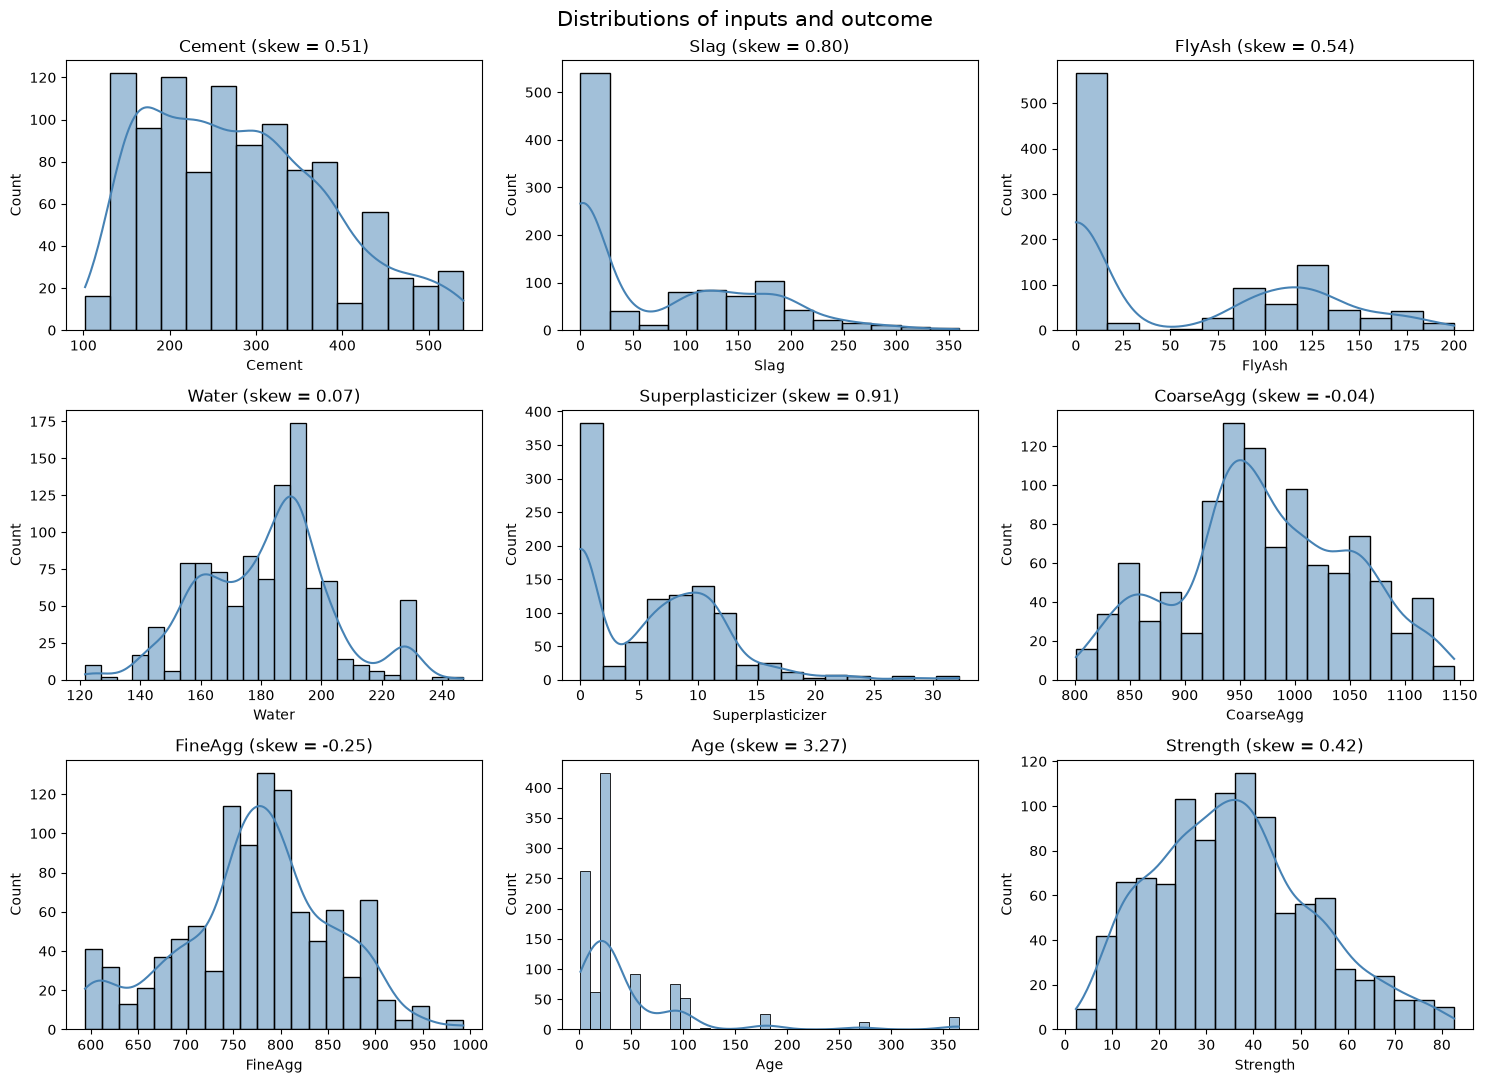

In [19]:
# Histograms (KDE) of all features and target variable
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
plt.suptitle("Distributions of inputs and outcome", fontsize=15)
plt.tight_layout()
plt.show()

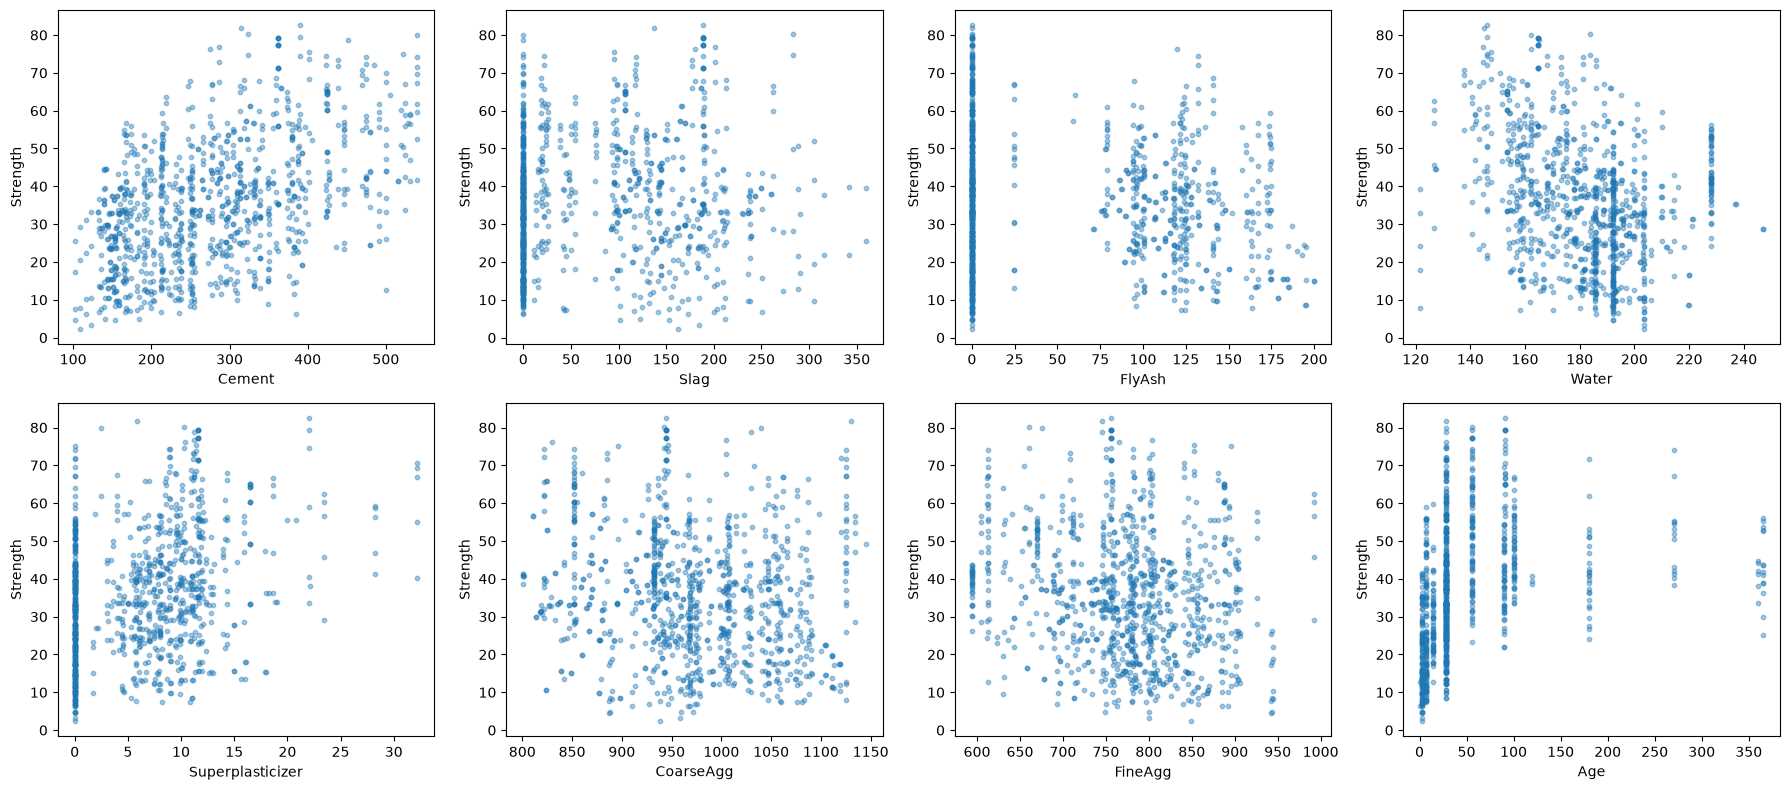

In [22]:
# Scatter plot of each input vs. strength
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, features):
    ax.scatter(df[col], df["Strength"], alpha=0.4, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel("Strength")
plt.tight_layout()
plt.show()

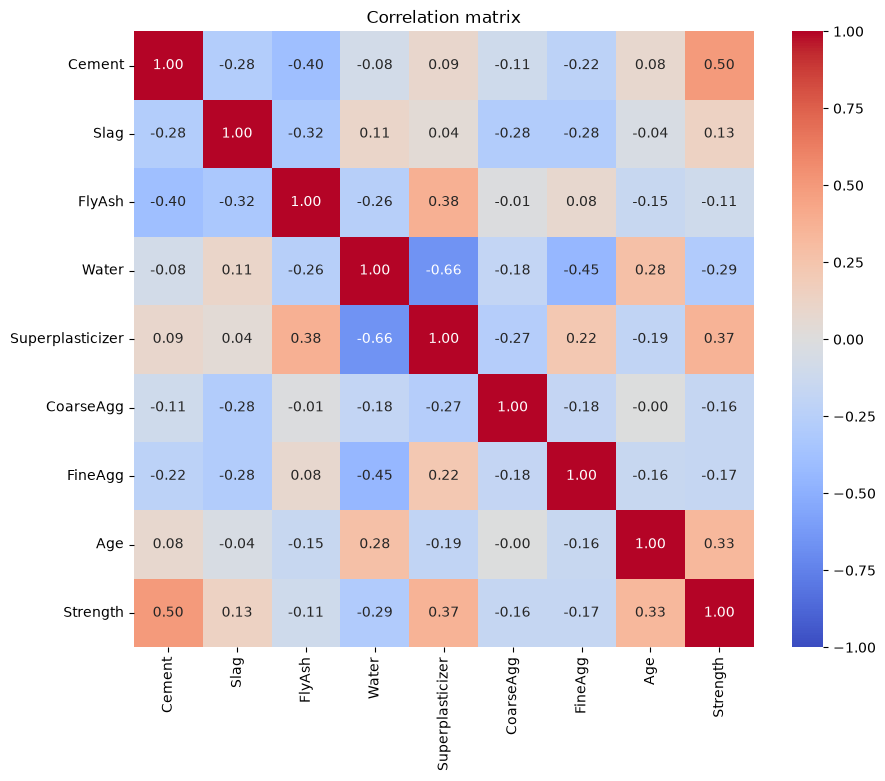

In [21]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### Preprocessing for all models

We drop the 25 exact duplicate rows, so no validation row has a copy in its training fold. We also replace Age with log(1 + Age), because Age has a skew of 3.27. We keep `df` unchanged for the plots above and use `df_model` for every model. Standardization happens later, inside each fold.

In [ ]:
df_model = df.drop_duplicates().reset_index(drop=True)
df_model = df_model.assign(Age=np.log1p(df_model['Age']))

print('Rows before:', len(df), '| rows after dropping duplicates:', len(df_model))
print('Age skew before:', round(df['Age'].skew(), 2), '| after log:', round(df_model['Age'].skew(), 2))

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

Architecture from Yeh (1998), which we adopt without tuning:

- Number of hidden layers = 1
- Number of hidden units = 8
- Learning rate = 1.0
- Momentum factor = 0.5
- Learning cycles = 3000

We keep the architecture (1 hidden layer, 8 units). The learning rate of 1.0 and the momentum factor belong to the paper's SGD-with-momentum optimizer. The lab requires Adam, so we use Adam with its usual learning rate of 0.01.

### 3.1 Settings and data

All settings are fixed before training (no tuning). We take the inputs X (8 features) and the outcome y (compressive strength, MPa) from `df_model`.

In [ ]:
SEED = 42
K_FOLDS = 5
N_HIDDEN = 8          # From the Yeh paper
LEARNING_RATE = 0.01
BATCH_SIZE = 32
EPOCHS = 500

X = df_model[features].to_numpy(dtype=np.float32)
y = df_model[target].to_numpy(dtype=np.float32).reshape(-1, 1)
print(X.shape, y.shape)

### 3.2 Model

In [ ]:
class ConcreteNet(nn.Module):
    def __init__(self, n_inputs, n_hidden):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, 1),  
        )

    def forward(self, x):
        return self.layers(x)


def train_model(model, loader, epochs, lr):
    loss_fn = nn.MSELoss()
    optimizer = Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
    return model

### 3.3 K-fold cross-validation

For each fold we:

1. Fit StandardScaler on the training fold only, then transform the training and validation folds (no leakage).
2. Convert the arrays to float32 tensors and wrap the training fold in a DataLoader.
3. Create a new ConcreteNet, so the weights start fresh in every fold.
4. Train with nn.MSELoss and Adam, then compute MSE, RMSE, MAE and R² on the validation fold.

In [ ]:
torch.manual_seed(SEED)
kf = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

nn_rows = []
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    scaler = StandardScaler().fit(X[train_idx])
    X_train = torch.tensor(scaler.transform(X[train_idx]), dtype=torch.float32)
    X_val = torch.tensor(scaler.transform(X[val_idx]), dtype=torch.float32)
    y_train = torch.tensor(y[train_idx])

    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
    model = train_model(ConcreteNet(X.shape[1], N_HIDDEN), loader, EPOCHS, LEARNING_RATE)

    model.eval()
    with torch.no_grad():
        y_pred = model(X_val).numpy()

    mse = mean_squared_error(y[val_idx], y_pred)
    nn_rows.append({'fold': fold, 'MSE': mse, 'RMSE': np.sqrt(mse),
                    'MAE': mean_absolute_error(y[val_idx], y_pred), 'R2': r2_score(y[val_idx], y_pred)})

nn_results = pd.DataFrame(nn_rows).set_index('fold')
nn_results

In [ ]:
print('PyTorch NN, mean across folds:')
nn_results.agg(['mean', 'std']).round(3)

### 3.4 Results

The table above shows the MSE, RMSE, MAE and R² for each of the 5 folds, along with the mean and standard deviation across them. We report the mean as the final performance of the network, which is an MSE of 43.2, an RMSE of 6.55 MPa, an MAE of 5.02 MPa and an R² of 0.836. In plain terms, the network explains about 84% of the variation in compressive strength, and a typical prediction is off by about 5 to 7 MPa, which is less than a fifth of the average strength in the dataset (about 35 MPa).

The folds were also fairly consistent, with R² ranging from 0.81 on fold 5 to 0.87 on fold 3, which gives a standard deviation of only 0.031. Since every fold used the same architecture and settings, the small spread that is left comes from which rows ended up in each split and from the random starting weights. Dropping the duplicate rows and log transforming Age both came from our plan in Part 1 and the skew we found in Part 2, and we decided on them before training, so they are preprocessing choices and not tuning. We kept the 1 hidden layer with 8 units from Yeh (1998) because the lab does not allow tuning.

We compare these numbers with the scikit-learn replication in Section 4 and with the SVM and Linear Regression in Section 5.

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [5]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [6]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

One specific challenge we had was collecting and communicate which techniques we would use for each section of this lab so that we could answer Question 1. This lab required planning and discussion in order for each of us to understand the process of building our neural network. We each came in with our own ideas and had some trouble communicating and aggreeing on one approach, which slowed us down and led to some back and forth while each was coding. Next time, we will use the in class lab time more wisely, spending it discussing in person what we want our final product to look like and writing down an agreed plan for each section. That way, we will all be on the same page from the start.